# plot_uncertainty — model spread in ΔT, CO₂ and AOD; cooling efficacy

Python port of `plot_uncertainty.m`. Shows, across the 6 GeoMIP models + SOCOL:
SSP5-8.5−SSP2-4.5 and G6sulfur−SSP2-4.5 warming, SSP CO₂ pathways, global
stratospheric AOD, and the cooling efficacy per unit AOD with a multi-model
±SE band.

All inputs live in the parent `../GeoMIP_G6Sulfur/` folder (external; no
in-folder generator), so they are read directly as `.nc`/`.mat`.

In [1]:
import sys, os
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, brighten, movmean

PARENT = "../GeoMIP_G6Sulfur"
tas = mu.ncread(f"{PARENT}/tas_timeseries_CMIP6_GeoMIP.nc", "tas")  # (model, exp, time) = (6,4,81)
xg = mu.loadmat(f"{PARENT}/tas_timeseries_SOCOL.mat")["x_glob_m_save_SOCOL"]  # (4,85)

fc1 = brewermap(7, "Set2")
time = np.arange(2020, 2101)
n_mod = ["CNRM-ESM2-1", "IPSL-CM6A-LR", "CESM2-WACCM", "UKESM1-0-LL",
         "MPI-ESM1-2-LR", "MPI-ESM1-2-HR", "SOCOL-MPI"]

# 6 models + SOCOL as 7th row (MATLAB rows 1/3/4 of x_glob_m_save_SOCOL = G6/ssp5/ssp2)
SSP585 = np.vstack([tas[:, 2, :], xg[2, 4:85]])
SSP245 = np.vstack([tas[:, 3, :], xg[3, 4:85]])
G6sulf = np.vstack([tas[:, 0, :], xg[0, 4:85]])

/Users/danielevisioni/Desktop/Articles_and_Research/Articles WIP/Uncertainties/python/mat_utils.py:236: UserWarning: WARNING: missing_value not used since it
cannot be safely cast to variable data type
  data = var[:]


## Panels 1–4: ΔT (SSP), ΔT (G6sulfur), CO₂ pathways, global AOD

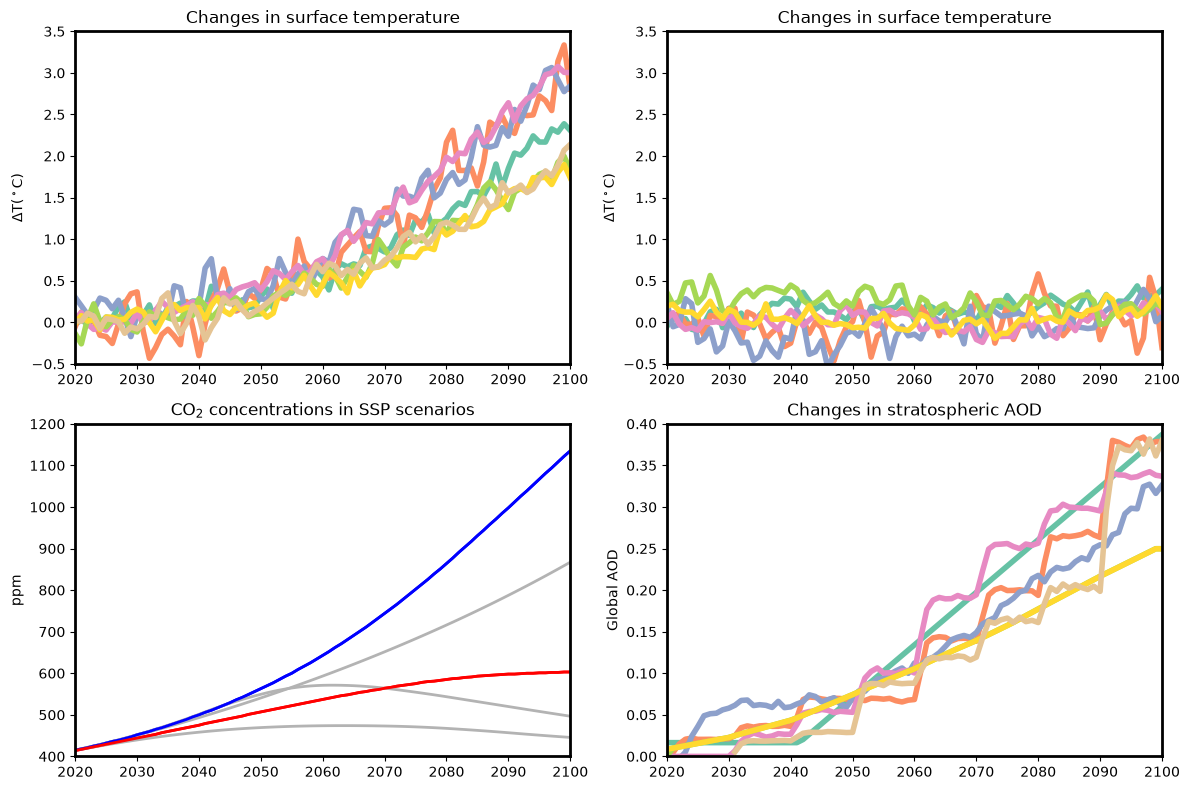

In [2]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

ax = axs[0, 0]
for i in range(7):
    ax.plot(time, SSP585[i] - SSP245[i], linewidth=4, color=fc1[i])
ax.set_ylabel(r"$\Delta$T($^\circ$C)"); ax.set_xlim(2020, 2100); ax.set_ylim(-.5, 3.5)
ax.set_title("Changes in surface temperature")

ax = axs[0, 1]
for i in range(6):
    ax.plot(time, G6sulf[i] - SSP245[i], linewidth=4, color=fc1[i])
ax.set_ylabel(r"$\Delta$T($^\circ$C)"); ax.set_xlim(2020, 2100); ax.set_ylim(-.5, 3.5)
ax.set_title("Changes in surface temperature")

co2 = mu.loadmat(f"{PARENT}/CO2_concentrations.mat")
ax = axs[1, 0]
yr = np.arange(2020, 2101)
for key, col in [("CO2_SSP585", "b"), ("CO2_SSP245", "r"), ("CO2_SSP370", [.7, .7, .7]),
                 ("CO2_SSP126", [.7, .7, .7]), ("CO2_SSP534", [.7, .7, .7])]:
    ax.plot(yr, np.asarray(co2[key], float).ravel()[5:86], color=col, linewidth=2)
ax.plot(yr, np.asarray(co2["CO2_SSP585"], float).ravel()[5:86], "b", linewidth=2)
ax.plot(yr, np.asarray(co2["CO2_SSP245"], float).ravel()[5:86], "r", linewidth=2)
ax.set_xlim(2020, 2100); ax.set_ylim(400, 1200); ax.set_ylabel("ppm")
ax.set_title("CO$_2$ concentrations in SSP scenarios")

AOD = np.asarray(mu.loadmat(f"{PARENT}/global_AOD.mat")["AOD"], float).copy()  # (81,7)
aod_socol = np.asarray(mu.loadmat(f"{PARENT}/aod_SOCOL.mat")["aod_SOCOL"], float).ravel()
AOD[0, 0] = AOD[1, 0]
AOD[:, 6] = np.nan
AOD[11:81, 6] = aod_socol
ax = axs[1, 1]
for i in range(7):
    ax.plot(time, AOD[:, i], linewidth=4, color=fc1[i])
ax.set_ylabel("Global AOD"); ax.set_xlim(2020, 2100); ax.set_ylim(0, .4)
ax.set_title("Changes in stratospheric AOD")
for a in axs.ravel():
    for s in a.spines.values():
        s.set_linewidth(2)
fig.tight_layout(); plt.show()
os.makedirs("py_outputs", exist_ok=True)
fig.savefig("py_outputs/uncertainties.png", dpi=300, bbox_inches="tight")

## Cooling efficacy per unit AOD (±SE across the 7 models)

mean efficacy 2080-2100: 6.703687780192522


/var/folders/t9/vl6_0lmn7w759j1nh0z6rblh0000gt/T/ipykernel_19075/1622003054.py:3: RuntimeWarning: invalid value encountered in divide
  ratio = (SSP585[:, 10:81] - G6sulf[:, 10:81]) / AOD[10:81, :].T   # (7, 71)


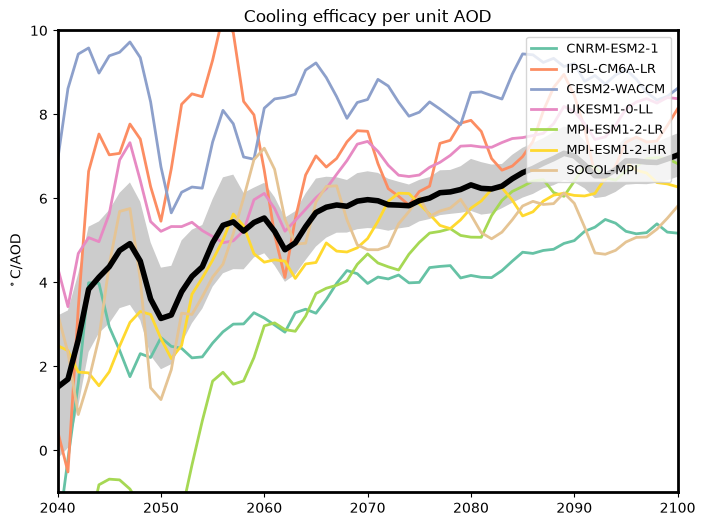

saved py_outputs/uncertainties.png, cooling_eff.png


In [3]:
time2 = np.arange(2030, 2101)
fig4, ax = plt.subplots(figsize=(8, 6))
ratio = (SSP585[:, 10:81] - G6sulf[:, 10:81]) / AOD[10:81, :].T   # (7, 71)
for i in range(7):
    ax.plot(time2, movmean(ratio[i], 3), linewidth=2, color=fc1[i])
tas_m = movmean(np.nanmean(ratio, axis=0), 3)
tasS = movmean(np.nanstd(ratio, axis=0, ddof=1), 3) / np.sqrt(7)
ax.plot(time2, tas_m, "k", linewidth=4)
ax.fill(np.concatenate([time2, time2[::-1]]),
        np.concatenate([tas_m + tasS, (tas_m - tasS)[::-1]]), "k", alpha=.2)
ax.legend(n_mod, loc="upper right", fontsize=9)
ax.set_ylabel(r"$^\circ$C/AOD"); ax.set_xlim(2040, 2100); ax.set_ylim(-1, 10)
ax.set_title("Cooling efficacy per unit AOD")
for s in ax.spines.values():
    s.set_linewidth(2)
print("mean efficacy 2080-2100:", np.nanmean(tas_m[50:71]))
plt.show()
fig4.savefig("py_outputs/cooling_eff.png", dpi=300, bbox_inches="tight")
print("saved py_outputs/uncertainties.png, cooling_eff.png")